In [151]:
import pandas as pd
import numpy as np


In [152]:
# parse_dates=['date'] — Converts the date column into datetime values instead of strings
# index_col=0 — Uses the first column (position 0) as the DataFrame index
train = pd.read_csv('../data/raw/train.csv', parse_dates=['date'], index_col=0)
test = pd.read_csv('../data/raw/test.csv', parse_dates=['date'])


# EDA

## Understanding the data
- Day-Ahead Market
    - when: electricity traded a day before delivery
    - purpose: plan electricity production and consumption
    - price: Day-ahead electricity price
    - price drives: expected supply and demand
    - Day-Ahead price = imbalance settlement price - spread (each in a different dataset)

- Imbalance Market
    - when: imbalances settled around real-time delivery
    - purpose: correct deviations from planned production and consumption
    - price: settlement price for deviations
    - price drives: hard-to-predict shortages and surpluses

- spread = imbalance settlement price - Day-ahead electricity price
    - positive - imbalance price more expensive than day-ahead price: e.g. unexpected shortage
    - negative - imbalance price cheaper than day-ahead price: e.g. unexpected surplus

- price spread predicted 15 minutes before

- wind = forcast wind electricity generation day-ahead (MW)
- solar = forcast solar electricity generation day-ahead (MW)
- load = forecast electricity consumption day-ahead (MW)



## Data quality

### Train data
- 140157 entries
- index is the date feature from 01-01-2020 till 31-12-2023
- 3 float64 features: wind, solar, load
- 1 float64 target: spread
- no missingness
- no duplicates

### Test data
- 24138 entries
- 5 columns: ID int64, date datatime64[us], and wind, solar, load float64
- target missing
- no missingness
- different formatting to train data:
    - date is a column in test, but index in train
    - test has an ID column, train does not
- no duplicates


In [153]:
train

,wind,solar,load,spread
date,,,,
2020-01-01 00:00:00,6084.0,0.0,43915.0,38.40
2020-01-01 00:15:00,5739.0,0.0,43770.0,-105.93
2020-01-01 00:30:00,5774.0,0.0,43267.0,-1.48
2020-01-01 00:45:00,5804.0,0.0,42934.0,3.97
2020-01-01 01:00:00,5791.0,0.0,42718.0,100.09
...,...,...,...,...
2023-12-31 22:45:00,29922.0,2.0,41550.0,102.06
2023-12-31 23:00:00,29546.0,3.0,40733.0,35.24
2023-12-31 23:15:00,29204.0,3.0,39805.0,78.57


In [154]:
train.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 140157 entries, 2020-01-01 00:00:00 to 2023-12-31 23:45:00
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   wind    140157 non-null  float64
 1   solar   140157 non-null  float64
 2   load    140157 non-null  float64
 3   spread  140157 non-null  float64
dtypes: float64(4)
memory usage: 5.3 MB


In [155]:
# Count fully duplicated rows
print(train.duplicated().sum())

0


In [156]:
test

,ID,date,wind,solar,load
0,0,2024-01-01 00:15:00,29540.0,2.0,37861.0
1,1,2024-01-01 00:30:00,29288.0,2.0,37554.0
2,2,2024-01-01 00:45:00,29545.0,2.0,36991.0
3,3,2024-01-01 01:00:00,29567.0,3.0,36733.0
4,4,2024-01-01 01:15:00,29470.0,2.0,36529.0
...,...,...,...,...,...
24133,24133,2024-09-08 09:45:00,3500.0,30591.0,48075.0
24134,24134,2024-09-08 10:00:00,3668.0,30567.0,48057.0
24135,24135,2024-09-08 10:15:00,3764.0,30700.0,48020.0
24136,24136,2024-09-08 10:30:00,3983.0,30724.0,47644.0


In [157]:
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 24138 entries, 0 to 24137
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   ID      24138 non-null  int64         
 1   date    24138 non-null  datetime64[us]
 2   wind    24138 non-null  float64       
 3   solar   24138 non-null  float64       
 4   load    24138 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1)
memory usage: 943.0 KB


In [158]:
# Count fully duplicated rows
print(test.duplicated().sum())

# Count duplicated rows without ID column
print(test.drop(columns=['ID']).duplicated().sum())


0
0



### Comparison
#### date
- train: from 01-01-2020 till 31-12-2023
- test: from 01-01-2024 till 08-09-2024

#### wind
- train: min=91, mean=11739, max=48158, std=9543
- test: min=251, mean=11996, max=46341, std=9597

#### solar
- train: min=0, mean=5815, max=41445, std=8990
- test: min=0, mean=8822, max=48630, std=12165

#### load
- train: min=30389, mean=54558, max=77752, std=9315
- test: min=31672, mean=52489, max=72686, std=8849

#### spread
- train: min=-9272, mean=1, max=15781, std=221, positive=51%, negative=49%
- test: missing

### Conclusions
- The train data precede the test data. The temporal gap between train and test is only one day.
- Wind and load features have similar means and stds between train and test data.
- Solar's mean and std increase by approximately 50% from the train to the test data.
- The time series consistently report observations every 15 minutes except for regular skips of exactly one observation on New Year's Eve and days of switching the winter time to the summer time in Germany.


In [159]:
# formatting test and train df for consistency (same columns, index, only target extra in train data)

# train has date as a column instead of index
train = train.reset_index()

# drop the ID column: 1. adds no predictive value and 2. only test data have ID
test = test.drop(columns=['ID'])

In [160]:
# differences in features
train.describe(include='all')

,date,wind,solar,load,spread
count,140157,140157.000000,140157.000000,140157.000000,140157.000000
mean,2021-12-31 07:00:36.743081,11739.139900,5815.140564,54558.491235,0.889667
min,2020-01-01 00:00:00,91.000000,0.000000,30389.000000,-9271.590000
25%,2020-12-31 00:00:00,4218.000000,1.000000,47053.000000,-61.510000
50%,2021-12-31 00:15:00,8827.000000,103.000000,54506.000000,3.230000
75%,2022-12-31 23:30:00,17058.000000,9260.000000,62236.000000,63.090000
max,2023-12-31 23:45:00,48158.000000,41445.000000,77752.000000,15781.480000
std,NaN,9542.520295,8990.140639,9315.313098,220.876249


In [161]:
test.describe(include='all')

,date,wind,solar,load
count,24138,24138.000000,24138.000000,24138.000000
mean,2024-05-05 17:32:07.740492,11996.372649,8822.020507,52488.733864
min,2024-01-01 00:15:00,251.000000,0.000000,31672.000000
25%,2024-03-03 20:48:45,4605.750000,2.000000,45141.000000
50%,2024-05-05 17:37:30,9311.500000,1020.000000,52034.500000
75%,2024-07-07 14:11:15,16998.000000,16141.750000,60034.750000
max,2024-09-08 10:45:00,46341.000000,48630.000000,72686.000000
std,NaN,9597.053504,12164.772502,8849.469627


In [162]:
# check the date is chronologically sorted
print(train['date'].is_monotonic_increasing)
print(test['date'].is_monotonic_increasing)

True
True


In [163]:
# check repeated timestamps
print(train['date'].duplicated().sum())
print(test['date'].duplicated().sum())

0
0


In [164]:
# check repeated timestamps
print(train['date'].diff().value_counts)

<bound method IndexOpsMixin.value_counts of 0                    NaT
1        0 days 00:15:00
2        0 days 00:15:00
3        0 days 00:15:00
4        0 days 00:15:00
               ...      
140152   0 days 00:15:00
140153   0 days 00:15:00
140154   0 days 00:15:00
140155   0 days 00:15:00
140156   0 days 00:15:00
Name: date, Length: 140157, dtype: timedelta64[us]>


In [165]:
train.loc[train['date'].diff().ne(pd.Timedelta(minutes=15)) & train['date'].diff().notna()]

,date,wind,solar,load,spread
8452,2020-03-29 01:15:00,17058.0,0.0,42069.0,81.56
35135,2021-01-01 00:15:00,3607.0,0.0,41824.0,39.76
43394,2021-03-28 01:15:00,17208.0,0.0,42880.0,34.87
70173,2022-01-01 00:15:00,24604.0,1.0,40205.0,32.24
78336,2022-03-27 01:15:00,3285.0,3.0,44371.0,-21.84
100123,2022-11-09 23:00:00,20704.0,3.0,51197.0,-95.59
105119,2023-01-01 00:15:00,29331.0,1.0,39862.0,267.02
113186,2023-03-26 01:15:00,25733.0,2.0,40835.0,-39.97


In [166]:
# calculate time difference between observations
diff = train['date'].diff()

# identify observations that are not 15 minutes apart
bad = diff.ne(pd.Timedelta(minutes=15))
bad.iloc[0] = False # exclude the first observation

# display positions before and after the jump
train.loc[bad | bad.shift(-1, fill_value=False)]

# The train series only skip an observation on the New Year's Eve (skip midnight) and German winter-to-summer time dates (March 29, 2020; March 28, 2021; March 27, 2022)

,date,wind,solar,load,spread
8451,2020-03-29 00:45:00,16784.0,0.0,42283.0,22.55
8452,2020-03-29 01:15:00,17058.0,0.0,42069.0,81.56
35134,2020-12-31 23:45:00,3673.0,0.0,42803.0,-47.55
35135,2021-01-01 00:15:00,3607.0,0.0,41824.0,39.76
43393,2021-03-28 00:45:00,17162.0,0.0,42585.0,36.23
43394,2021-03-28 01:15:00,17208.0,0.0,42880.0,34.87
70172,2021-12-31 23:45:00,25313.0,1.0,41364.0,98.58
70173,2022-01-01 00:15:00,24604.0,1.0,40205.0,32.24
78335,2022-03-27 00:45:00,3466.0,3.0,44684.0,-165.35
78336,2022-03-27 01:15:00,3285.0,3.0,44371.0,-21.84


In [167]:
# calculate time difference between observations
diff = test['date'].diff()

# identify observations that are not 15 minutes apart
bad = diff.ne(pd.Timedelta(minutes=15))
bad.iloc[0] = False # exclude the first observation

# display positions before and after the jump
test.loc[bad | bad.shift(-1, fill_value=False)]

# The test series only skip one observation on the German winter-to-summer time switch on March 31, 2024

,date,wind,solar,load
8642,2024-03-31 00:45:00,6350.0,2.0,38364.0
8643,2024-03-31 01:15:00,6864.0,2.0,38446.0


In [168]:
train.select_dtypes('number').skew()     # Distribution asymmetry

wind      1.088769
solar     1.557297
load     -0.033455
spread    9.878630
dtype: float64

In [169]:
train.select_dtypes('number').corr()

,wind,solar,load,spread
wind,1.000000,-0.214390,0.108594,0.012928
solar,-0.214390,1.000000,0.303103,-0.052183
load,0.108594,0.303103,1.000000,0.001718
spread,0.012928,-0.052183,0.001718,1.000000


In [170]:
# proportion of positive (True) spread values and negative (False) spread values
np.sign(train['spread']).value_counts(normalize=True)

spread
 1.0    0.509857
-1.0    0.490129
 0.0    0.000014
Name: proportion, dtype: float64

## Target Analysis

### Outliers
- 9.45% of spread values are considered outliers by the 1.5 IQR Rule for Outlier Detection
  - substantial proportion of observations are outliers => we can't just remove them
- outliers occur in both tails of spread: 53% outliers are positive and 47% are negative
  - evaluate model performance separately for positive and negative outliers
- negative outliers sligthly more severe than positive ones: mean of positive outliers 428, mean of negative ones 394
  - both negative and positive outliers seem to be of the same importance in modelling
- outliers are concentrated in time: 1% occurs in 2020, 31% in 2022
  - distribution shift (greater weight on recent observations), regime change (make regime-aware model/features)
- 66% of outliers are consecutive (preceded by an outlier)
- conclusion: the effect of outliers on the model performance needs to be accounted for because outliers are

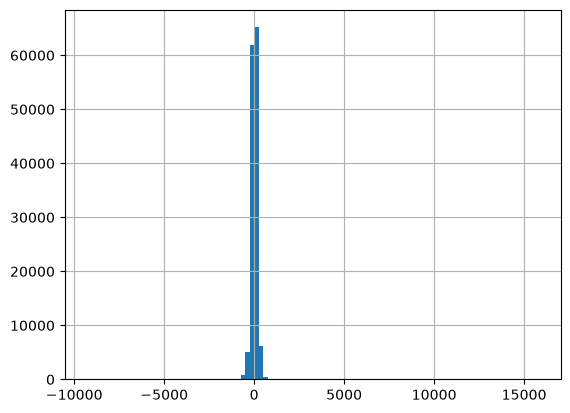

In [171]:
import matplotlib.pyplot as plt
from scipy import stats

spread = train['spread']
train['spread'].hist(bins=100)
plt.show()

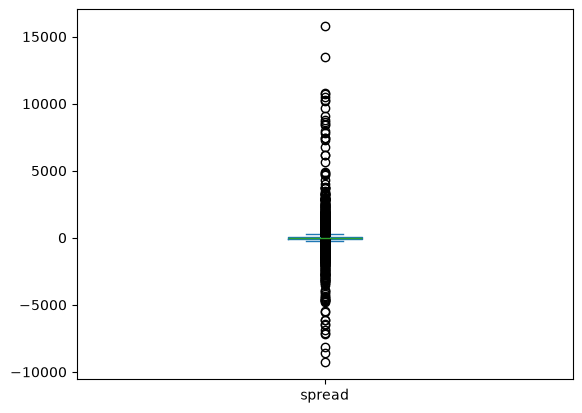

In [172]:
# outliers occur in both tails
spread.plot.box()
plt.show()

In [173]:
# The 1.5 IQR Rule for Outlier Detection
# data falling below q1 - 1.5 * iqr or above q3 + 1.5 * iqr are considered outliers
q1, q3 = spread.quantile([0.25, 0.75])
iqr = q3 - q1

outliers = (spread < q1 - 1.5 * iqr) | (spread > q3 + 1.5 * iqr)

print(f"Interquartile range: {iqr}")
print(f"Outlier lower bound: {q1 - 1.5 * iqr}")
print(f"Outlier upper bound: {q3 + 1.5 * iqr}")
print(f"Interquartile range: {iqr}")
print(f"Outliers: {outliers.sum():,}")
print(f"Percentage: {outliers.mean():.2%}")

Interquartile range: 124.6
Outlier lower bound: -248.40999999999997
Outlier upper bound: 249.98999999999998
Interquartile range: 124.6
Outliers: 13,246
Percentage: 9.45%


In [174]:
# shows quantiles of the spread: outliers are extreme in scale
# middle 98% observations are between -449 and 393
# smallest 0.1% observations are between -1114 and -9272
# greatest 0.1% observations are between 1278 and 15781

spread.quantile([0, .001, .01, .5, .99, .999, 1])

0.000    -9271.59000
0.001    -1113.92012
0.010     -449.23960
0.500        3.23000
0.990      393.18760
0.999     1277.64124
1.000    15781.48000
Name: spread, dtype: float64

In [175]:
# make an extra column for identification of outliers
# outliers occur very irregularly across years:
# ie. only 1% of spreads in 2020 are outliers compared to 31% of spread being outliers in 2022
train.assign(outlier=outliers).groupby(
    train['date'].dt.year
)['outlier'].mean()


date
2020    0.008738
2021    0.023460
2022    0.309334
2023    0.037302
Name: outlier, dtype: float64

In [231]:
# Temporal clustering of outliers
# outliers - a vector identifying outliers
# outliers.shift(fill_value=False) - shifts vector entries by one down (filling in the upper most value with False)
# outliers & outliers.shift(fill_value=False) is True element-wise when an outlier was preceeded by another outlier
# (outliers & outliers.shift(fill_value=False)).sum() sums all the following outliers / all outliers


# 66% of outliers are preceeded by other outliers => the outliers are clustered in time
print((outliers & outliers.shift(fill_value=False)).sum() / outliers.sum())


0.6598973274950929


In [177]:
# Outlier symmetry
# selects outliers from train, find proportion of positive and negative outliers
train.loc[outliers, 'spread'].gt(0).value_counts(normalize=True)

spread
True     0.531104
False    0.468896
Name: proportion, dtype: float64

In [178]:
# select spreads of outliers from train
s = train.loc[outliers, 'spread']

# find the count, median, and max of positive and negative outliers
s.abs().groupby(np.sign(s)).agg(['count', 'median', 'mean', 'max'])

# there are slightly fewer negative outlier (6211) than positive ones (7035)
# but the median and mean (345 and 428) of negative outliers are higher than the ones (273 and 394) of positive outliers

,count,median,mean,max
spread,,,,
-1.0,6211,346.94,428.194160,9271.59
1.0,7035,272.70,393.503222,15781.48


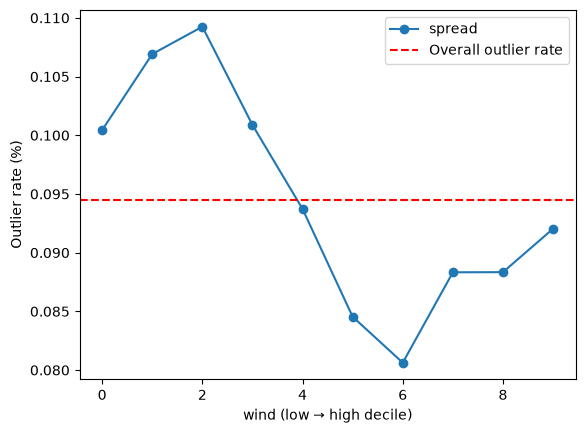

In [230]:
f = "wind"  # Choose a wind, solar, or load feature

bins = pd.qcut(train[f], 10, labels=False, duplicates='drop')
rates = pd.Series(outliers, index=train.index).groupby(bins).mean()

rates.plot(marker='o')
plt.axhline(np.mean(outliers), color='red', linestyle='--', label='Overall outlier rate')
plt.xlabel(f'{f} (low → high decile)')
plt.ylabel('Outlier rate (%)')
plt.legend()
plt.show()

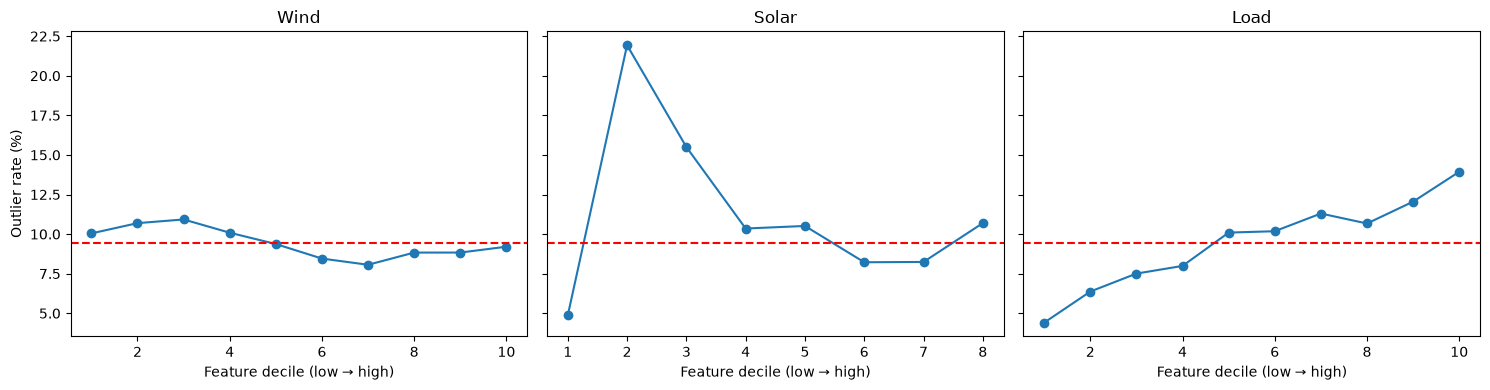

In [204]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

# for each feature: wind, solar, load
for ax, feature in zip(axes, ['wind', 'solar', 'load']):
    bins = pd.qcut(train[feature], 10, labels=False, duplicates='drop')
    rates = pd.Series(outliers, index=train.index).groupby(bins).mean() * 100

    ax.plot(rates.index + 1, rates.values, marker='o')
    ax.axhline(np.mean(outliers) * 100, color='red', linestyle='--')

    ax.set_title(feature.capitalize())
    ax.set_xlabel('Feature decile (low → high)')

axes[0].set_ylabel('Outlier rate (%)')
plt.tight_layout()
plt.show()

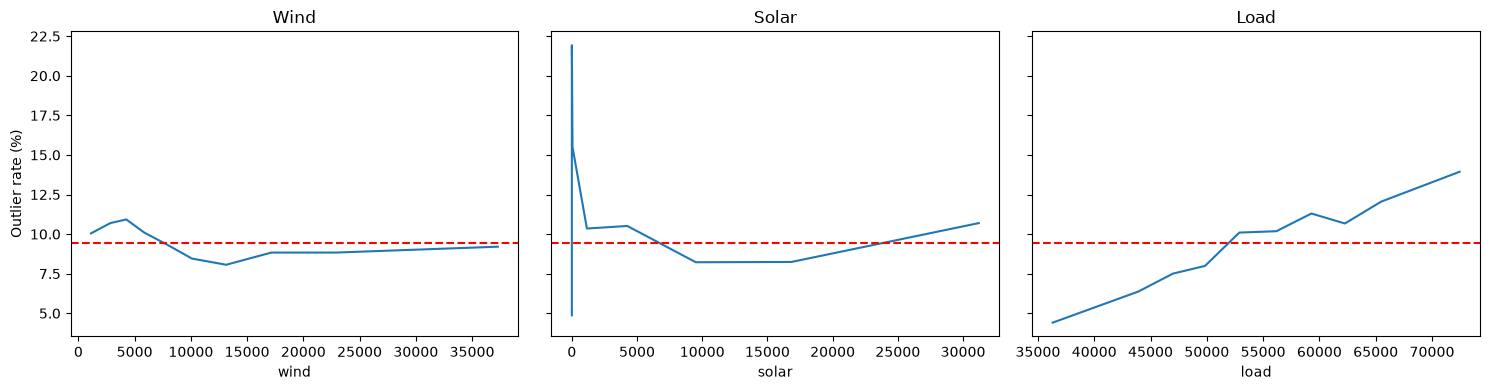

In [205]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, feature in zip(axes, ['wind', 'solar', 'load']):
    bins = pd.qcut(train[feature], 10, duplicates='drop') # duplicates='drop' removes duplicate bins
    rates = pd.Series(outliers, index=train.index).groupby(bins, observed=True).mean() * 100

    ax.plot([interval.mid for interval in rates.index], rates.values)
    ax.axhline(np.mean(outliers) * 100, color='red', linestyle='--')

    ax.set_title(feature.capitalize())
    ax.set_xlabel(feature)

axes[0].set_ylabel('Outlier rate (%)')
plt.tight_layout()
plt.show()

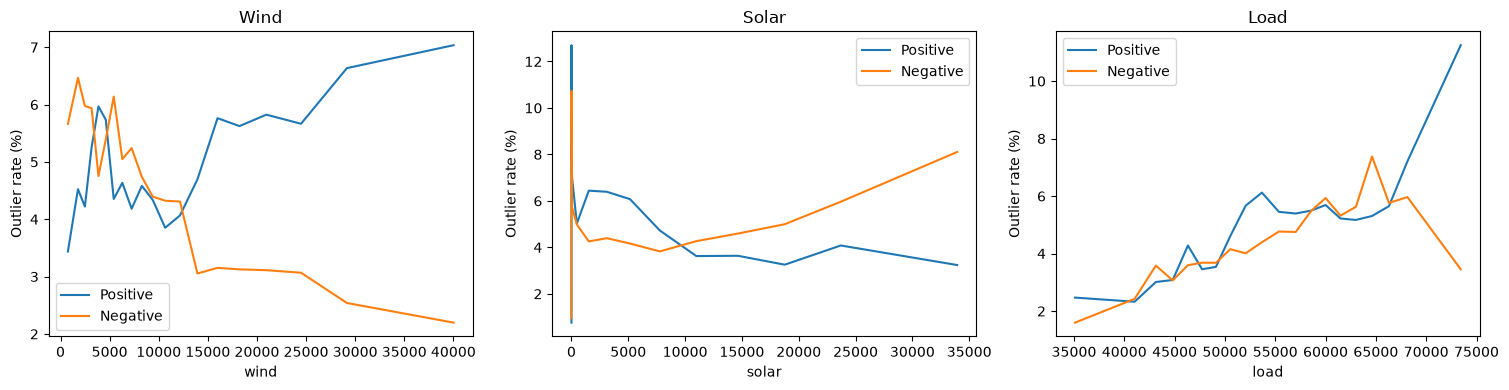

In [207]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, ['wind', 'solar', 'load']):
    bins = pd.qcut(train[feature], 20, duplicates='drop')

    rates = pd.DataFrame({
        'Positive': outliers & (train['spread'] > 0),
        'Negative': outliers & (train['spread'] < 0)
    }).groupby(bins, observed=True).mean() * 100

    rates.index = [interval.mid for interval in rates.index]
    rates.plot(ax=ax)

    ax.set_title(feature.capitalize())
    ax.set_xlabel(feature)
    ax.set_ylabel('Outlier rate (%)')

plt.tight_layout()
plt.show()

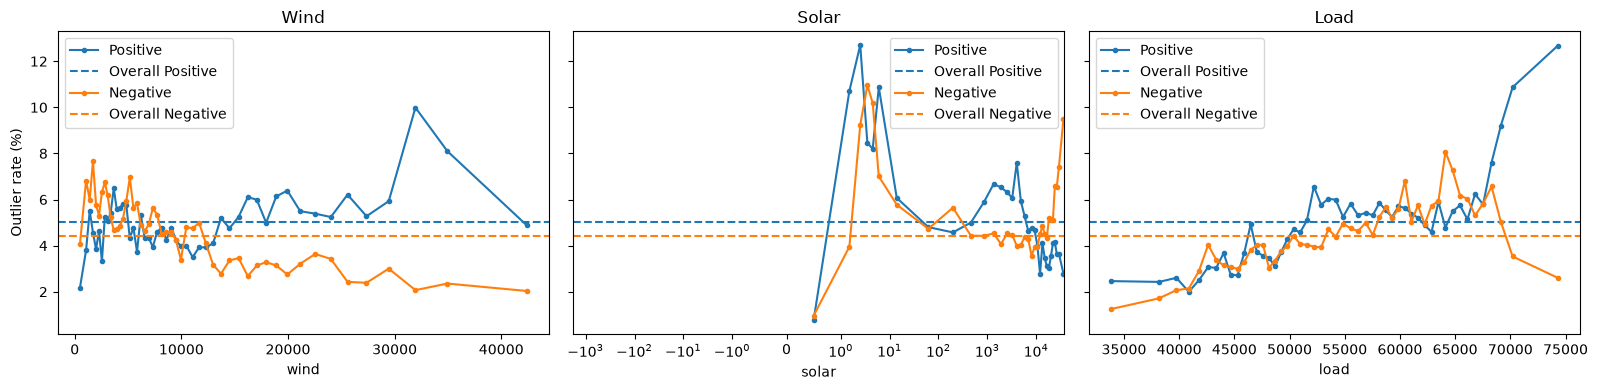

In [208]:
positive = outliers & (train['spread'] > 0)
negative = outliers & (train['spread'] < 0)

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

for ax, feature in zip(axes, ['wind', 'solar', 'load']):
    bins = pd.qcut(train[feature], 50, duplicates='drop')

    rates = pd.DataFrame({
        'Positive': positive,
        'Negative': negative
    }).groupby(bins, observed=True).mean() * 100

    x = [interval.mid for interval in rates.index]

    for sign, color, mask in [
        ('Positive', 'C0', positive),
        ('Negative', 'C1', negative)
    ]:
        ax.plot(x, rates[sign], color=color, marker='.', label=sign)
        ax.axhline(mask.mean() * 100, color=color,
                   linestyle='--', label=f'Overall {sign}')

    if feature == 'solar':
        ax.set_xscale('symlog', linthresh=1)

    ax.set_title(feature.capitalize())
    ax.set_xlabel(feature)
    ax.legend()

axes[0].set_ylabel('Outlier rate (%)')
plt.tight_layout()
plt.show()

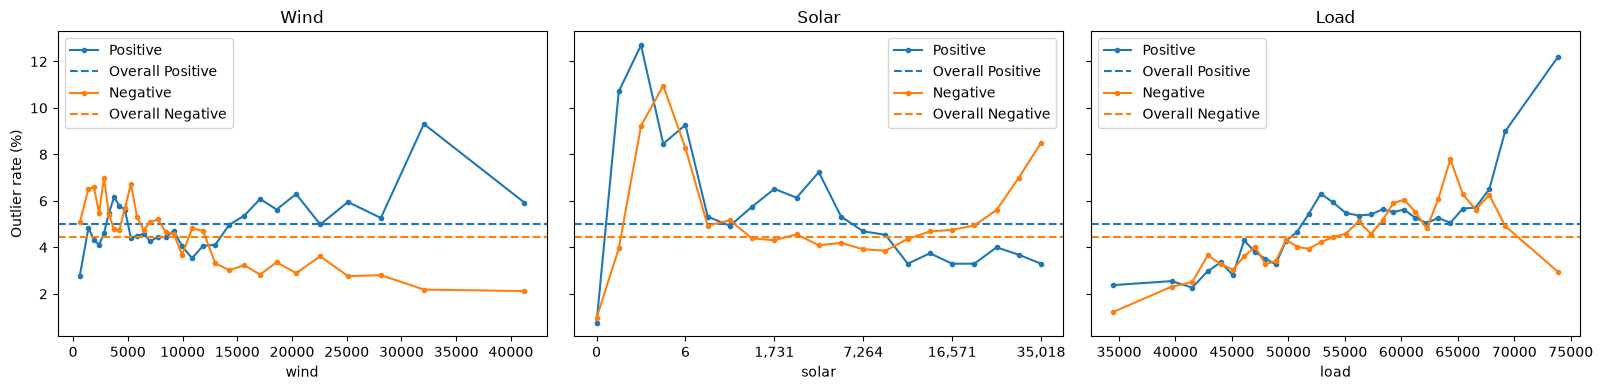

In [220]:
positive = outliers & (train['spread'] > 0)
negative = outliers & (train['spread'] < 0)

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

for ax, feature in zip(axes, ['wind', 'solar', 'load']):
    bins = pd.qcut(train[feature], 30, duplicates='drop')

    rates = pd.DataFrame({
        'Positive': positive,
        'Negative': negative
    }).groupby(bins, observed=True).mean() * 100

    if feature == 'solar':
        x = np.arange(len(rates))
        ticks = np.linspace(0, len(rates) - 1, 6, dtype=int)
        ax.set_xticks(ticks)
        ax.set_xticklabels([f'{rates.index[i].mid:,.0f}' for i in ticks])
    else:
        x = [interval.mid for interval in rates.index]

    for sign, color, mask in [
        ('Positive', 'C0', positive),
        ('Negative', 'C1', negative)
    ]:
        ax.plot(x, rates[sign], color=color, marker='.', label=sign)
        ax.axhline(mask.mean() * 100, color=color,
                   linestyle='--', label=f'Overall {sign}')

    ax.set_title(feature.capitalize())
    ax.set_xlabel(feature)
    ax.legend()

axes[0].set_ylabel('Outlier rate (%)')
plt.tight_layout()
plt.show()

# features contain some signal about the outliers
# wind may predict the direction of extreme spreads (outliers): positive outliers increase, while negative ones decrease, with wind
# high expected load is associated with positive outliers in spread, and absence of negative outliers

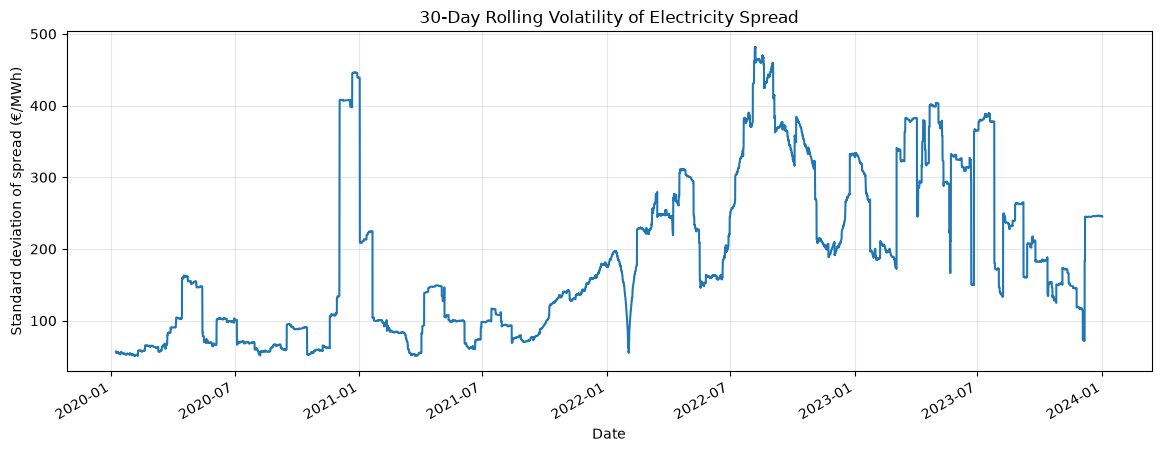

In [221]:
import matplotlib.pyplot as plt

s = train.sort_values('date').set_index('date')['spread']


volatility = s.rolling('30D', min_periods=96*7).std()

plt.figure(figsize=(14, 5))
volatility.plot()

plt.title('30-Day Rolling Volatility of Electricity Spread')
plt.xlabel('Date')
plt.ylabel('Standard deviation of spread (€/MWh)')
plt.grid(alpha=0.3)
plt.show()

# plot interpretation: volatility of spread is time-dependent (seasonality? entire year differences, volatility changes are sometime abrupt)


In [222]:
# distribution shift
s = train['spread']
year = train['date'].dt.year

summary = train.groupby(year)['spread'].agg(
    median='median',
    std='std',
    q01=lambda x: x.quantile(.01),
    q99=lambda x: x.quantile(.99),
    iqr=lambda x: x.quantile(.75) - x.quantile(.25),
    positive_rate=lambda x: (x > 0).mean()
)

display(summary)

,median,std,q01,q99,iqr,positive_rate
date,,,,,,
2020,2.210,152.740869,-142.9694,186.3946,56.6200,0.512936
2021,3.150,114.290293,-269.3175,259.6398,104.4625,0.510531
2022,23.560,298.257909,-599.1560,548.7235,339.2550,0.514651
2023,0.515,264.483909,-313.8584,351.6869,133.6750,0.501313


In [225]:
features = ['wind', 'solar', 'load']

for feature in features:
    print(f"\n{feature}")
    print("Train:", train[feature].quantile([.01, .5, .99]))
    print("Test: ", test[feature].quantile([.01, .5, .99]))


wind
Train: 0.01      625.00
0.50     8827.00
0.99    39140.32
Name: wind, dtype: float64
Test:  0.01      631.00
0.50     9311.50
0.99    42469.04
Name: wind, dtype: float64

solar
Train: 0.01        0.00
0.50      103.00
0.99    33316.88
Name: solar, dtype: float64
Test:  0.01        0.00
0.50     1020.00
0.99    42069.26
Name: solar, dtype: float64

load
Train: 0.01    35787.68
0.50    54506.00
0.99    71782.00
Name: load, dtype: float64
Test:  0.01    35366.37
0.50    52034.50
0.99    69726.26
Name: load, dtype: float64
